# 29. CN7 온도 교란 구간 — 재가동 직후를 빼면 임계값이 의미가 생기나

28번과 같은 구간 점수 E (호퍼온도↑·금형온도↓, 최근 5샷 평균) / **CN7만**
- **재가동 직후 N샷 제외** (N = 15 기본, 10·20 민감도). 재가동 = Run 시작 또는 5분 넘는 정지 뒤
  → 워밍업 중 온도 흔들림은 공정상 당연 → 가스 결과와 무관하게 정할 수 있는 조건
- **임계값도 재가동 제외 정상 생산(unlabeled)에서 다시 계산**
- 임계값 하나를 고르지 않고 **여러 오경보율(q)에서 결과를 표로** → 현장이 고를 운영 옵션

⚠ 규칙 방향은 R1에서 정함 → R1 탐지 수는 사후 확인. **정상 생산 쪽 수치(오경보 빈도, 정점 백분위)는 라벨과 무관한 근거**

In [1]:
import os
import pandas as pd
from thermal_cn7 import load, tradeoff, peak_rank, plot_tradeoff
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
OUT = './outputs/thermal_cn7'
os.makedirs(OUT, exist_ok=True)

LAB, REF = load('cn7')
print('재가동 후 15샷 이내 비율 — 정상생산', f"{(REF['since_restart'] <= 15).mean():.1%}", '/ labeled', f"{(LAB['since_restart'] <= 15).mean():.1%}")

재가동 후 15샷 이내 비율 — 정상생산 1.5% / labeled 8.7%


## 1. R1 가스 언덕은 정상 생산에서 얼마나 드문가 (라벨과 무관한 핵심 근거)
**상위 1% 안 + 같은 높이 언덕이 드묾** → 주의 경보 후보 / **상위 5~10% 이상** → 정상에서도 흔한 출렁임

In [2]:
PK = pd.DataFrame([peak_rank(LAB, REF, n) for n in (0, 10, 15, 20)])
PK.to_csv(f'{OUT}/peak_rank.csv', index=False, encoding='utf-8-sig')
display(PK.round(3))

,재가동 제외 샷,R1 가스 언덕 정점 E,정상생산에서 상위 %,정상생산에서 같은 높이 이상 언덕 수,"정상생산 1,000샷당 그런 언덕",labeled 다른 구간의 같은 높이 이상 언덕 수
0,0,4.326,1.081,19,3.669,5
1,10,4.326,1.015,17,3.318,3
2,15,4.326,1.020,17,3.334,2
3,20,4.326,1.025,17,3.350,2


## 2. 오경보율별 운영 옵션 (재가동 제외 0 / 10 / 15 / 20샷)

In [3]:
T = pd.concat([tradeoff(LAB, REF, n) for n in (0, 10, 15, 20)], ignore_index=True)
T.to_csv(f'{OUT}/tradeoff.csv', index=False, encoding='utf-8-sig')
for n, g in T.groupby('재가동 제외 샷'):
    print(f'재가동 후 {n}샷 제외'); display(g.drop(columns='재가동 제외 샷').round(3))

재가동 후 0샷 제외


,q,정상 오경보율,임계값 E,"정상생산 1,000샷당 에피소드",labeled 정상 샷 경보 비율,labeled 에피소드,불량 관련 에피소드(구간 내·직후 10샷),불량 없는 에피소드,가스 탐지,첫 미성형보다 먼저 울린 샷 수
0,0.900,10%,2.670,24.329,0.059,36,2,34,5/11,6
1,0.950,5%,3.165,13.902,0.028,18,1,17,4/11,4
2,0.970,3%,3.548,8.496,0.016,12,1,11,2/11,2
3,0.980,2%,3.871,6.565,0.010,8,2,6,1/11,2
4,0.990,1%,4.397,3.669,0.005,4,1,3,0/11,0
5,0.995,0.5%,4.681,3.089,0.004,3,0,3,0/11,0


재가동 후 10샷 제외


,q,정상 오경보율,임계값 E,"정상생산 1,000샷당 에피소드",labeled 정상 샷 경보 비율,labeled 에피소드,불량 관련 에피소드(구간 내·직후 10샷),불량 없는 에피소드,가스 탐지,첫 미성형보다 먼저 울린 샷 수
6,0.900,10%,2.662,24.200,0.051,35,2,33,5/11,6
7,0.950,5%,3.140,13.856,0.020,20,2,18,5/11,6
8,0.970,3%,3.515,8.197,0.009,10,1,9,2/11,2
9,0.980,2%,3.832,6.635,0.004,7,2,5,1/11,2
10,0.990,1%,4.339,3.318,0.001,2,1,1,0/11,0
11,0.995,0.5%,4.639,2.927,0.001,1,0,1,0/11,0


재가동 후 15샷 제외


,q,정상 오경보율,임계값 E,"정상생산 1,000샷당 에피소드",labeled 정상 샷 경보 비율,labeled 에피소드,불량 관련 에피소드(구간 내·직후 10샷),불량 없는 에피소드,가스 탐지,첫 미성형보다 먼저 울린 샷 수
12,0.900,10%,2.661,23.730,0.047,33,2,31,5/11,6
13,0.950,5%,3.146,14.120,0.017,18,2,16,5/11,6
14,0.970,3%,3.520,8.237,0.007,8,1,7,2/11,2
15,0.980,2%,3.843,6.472,0.002,5,2,3,1/11,2
16,0.990,1%,4.344,3.334,0.000,1,1,0,0/11,0
17,0.995,0.5%,4.642,2.942,0.000,0,0,0,0/11,0


재가동 후 20샷 제외


,q,정상 오경보율,임계값 E,"정상생산 1,000샷당 에피소드",labeled 정상 샷 경보 비율,labeled 에피소드,불량 관련 에피소드(구간 내·직후 10샷),불량 없는 에피소드,가스 탐지,첫 미성형보다 먼저 울린 샷 수
18,0.900,10%,2.664,23.650,0.047,33,2,31,5/11,6
19,0.950,5%,3.152,13.993,0.017,16,1,15,4/11,4
20,0.970,3%,3.530,8.277,0.007,8,1,7,2/11,2
21,0.980,2%,3.845,6.504,0.002,4,2,2,1/11,2
22,0.990,1%,4.345,3.350,0.000,1,1,0,0/11,0
23,0.995,0.5%,4.646,2.956,0.000,0,0,0,0/11,0


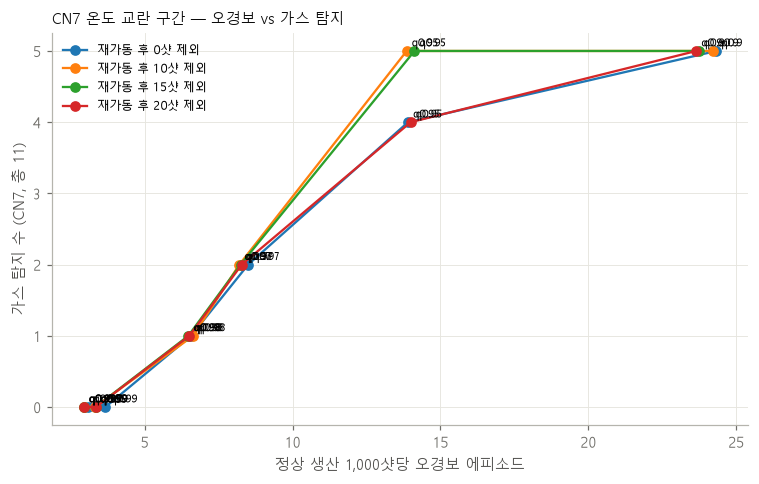

In [4]:
plot_tradeoff(T, save=f'{OUT}/tradeoff.png')

## 해석 가이드
| 결과 | 판단 |
|---|---|
| 재가동 제외 후 R1 정점이 정상생산 상위 1% 안, 같은 높이 언덕이 1,000샷당 1개 미만 | 드문 현상 → 4장 'CN7 가스 주의 경보' 제안 가능 (단, 가스 에피소드 1개 근거라고 명시) |
| 가스를 몇 개라도 잡는 q에서 labeled 불량 없는 에피소드가 여러 개 | 정상 구간에도 비슷한 언덕이 흔함 → 3장 가설로만 |
| 재가동 제외 샷 수(10/15/20)에 따라 결론이 크게 바뀜 | 조건에 민감 → 신뢰도 낮음 |